# Phần 3 - Khởi tạo trọng số

In [1]:
import sys; sys.path.append("../src")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils import ACTS, INITS, load_mnist, make_mlp, train, activations_per_layer

REPORTS = Path("../reports"); REPORTS.mkdir(exist_ok=True)
data = load_mnist()
WIDTHS = [784] + [256] * 5 + [10]       # đủ sâu để khác biệt giữa các cách khởi tạo lộ rõ

## Bước 10. 4 cách khởi tạo (ReLU, cùng lr/seed): loss và accuracy theo epoch

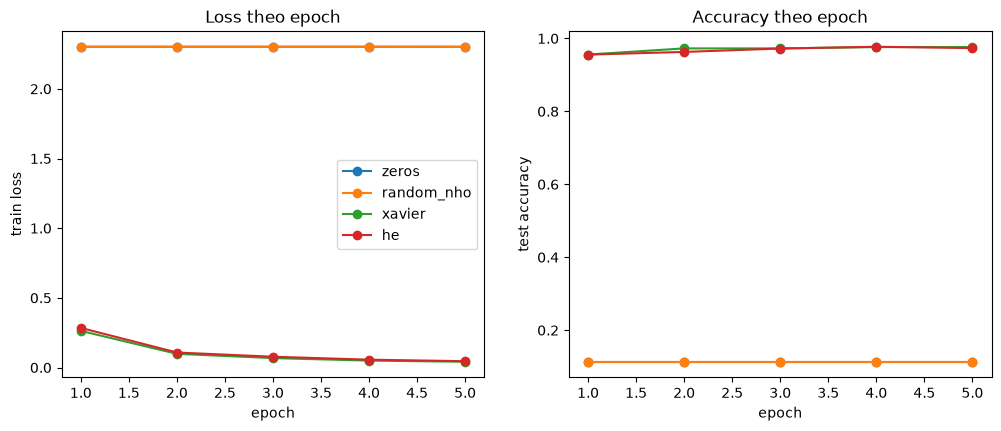

In [2]:
curves = {}
for init in INITS:
    hist, _ = train(make_mlp(WIDTHS, ACTS["ReLU"], init), data, epochs=5, lr=0.05)
    curves[init] = pd.DataFrame(hist)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4.5))
for init, d in curves.items():
    a.plot(d.epoch, d.loss, "o-", label=init); b.plot(d.epoch, d.acc, "o-", label=init)
a.set(xlabel="epoch", ylabel="train loss", title="Loss theo epoch"); a.legend()
b.set(xlabel="epoch", ylabel="test accuracy", title="Accuracy theo epoch")
fig.savefig(REPORTS / "init_comparison.png", dpi=150, bbox_inches="tight")

## Bước 11. Zeros: các neuron giống hệt nhau mãi mãi
Dùng sigmoid vì với ReLU, z=0 làm đạo hàm = 0 nên trọng số đứng yên hoàn toàn (không thấy được cơ chế đối xứng).

In [3]:
for init in ["zeros", "he"]:
    model = make_mlp([784, 128, 10], ACTS["Sigmoid"], init)
    train(model, data, epochs=3, lr=0.1)
    W = model[0].weight.detach().cpu()                 # (128 neuron, 784 trọng số)
    print(f"[{init}] 5 neuron đầu, 6 trọng số đầu:\n{W[:5, :6].numpy().round(5)}")
    print(f"[{init}] chênh lệch lớn nhất giữa 128 neuron = {(W - W[0]).abs().max().item():.2e}\n")

[zeros] 5 neuron đầu, 6 trọng số đầu:
[[0.0137 0.0137 0.0137 0.0137 0.0137 0.0137]
 [0.0137 0.0137 0.0137 0.0137 0.0137 0.0137]
 [0.0137 0.0137 0.0137 0.0137 0.0137 0.0137]
 [0.0137 0.0137 0.0137 0.0137 0.0137 0.0137]
 [0.0137 0.0137 0.0137 0.0137 0.0137 0.0137]]
[zeros] chênh lệch lớn nhất giữa 128 neuron = 2.87e-01

[he] 5 neuron đầu, 6 trọng số đầu:
[[ 2.723e-02 -1.724e-02 -3.776e-02  7.703e-02 -3.607e-02  3.151e-02]
 [ 7.665e-02 -4.481e-02  6.484e-02 -3.713e-02 -3.378e-02  4.377e-02]
 [ 6.980e-03 -2.894e-02 -2.197e-02 -5.260e-03  8.435e-02 -3.746e-02]
 [ 4.300e-03  3.725e-02 -7.530e-03 -2.955e-02  2.207e-02  1.626e-02]
 [-5.980e-03 -6.805e-02 -5.000e-05  9.790e-03 -5.766e-02 -9.921e-02]]
[he] chênh lệch lớn nhất giữa 128 neuron = 7.69e-01



## Bước 12. Phân phối activation qua từng tầng ngay sau khởi tạo

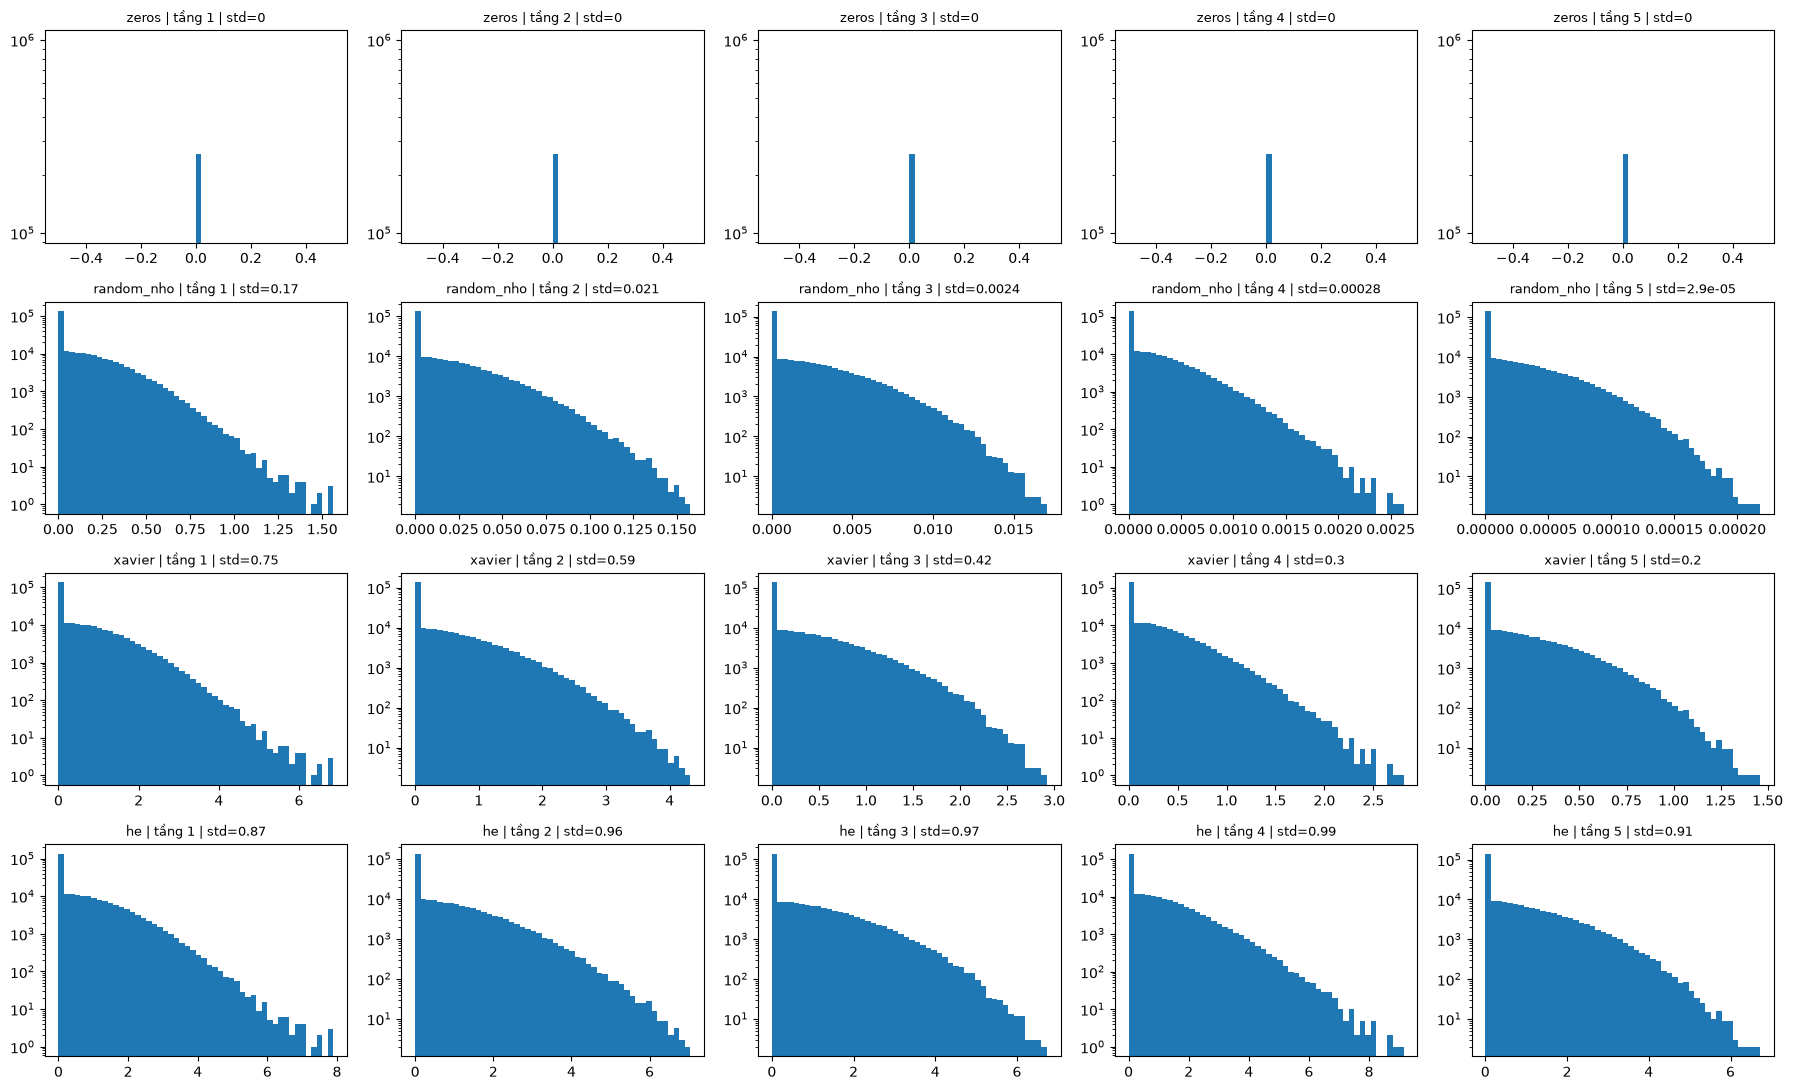

In [4]:
X = data[0][:1000]
fig, axes = plt.subplots(4, 5, figsize=(18, 11))
for r, init in enumerate(INITS):
    acts = activations_per_layer(make_mlp(WIDTHS, ACTS["ReLU"], init).to(X.device), X)
    for c, a in enumerate(acts):
        axes[r, c].hist(a.numpy(), bins=50, log=True)
        axes[r, c].set_title(f"{init} | tầng {c+1} | std={a.std():.2g}", fontsize=9)
fig.tight_layout()
fig.savefig(REPORTS / "init_activation_dist.png", dpi=130, bbox_inches="tight")

## Bước 13. BatchNorm có làm mạng bớt nhạy với khởi tạo không?

In [5]:
rows = [dict(bn=False, init=k, final_loss=d.loss.iloc[-1], test_acc=d.acc.iloc[-1]) for k, d in curves.items()]
for init in INITS:                                     # bản không BN đã train ở bước 10
    hist, _ = train(make_mlp(WIDTHS, ACTS["ReLU"], init, bn=True), data, epochs=5, lr=0.05)
    rows.append(dict(bn=True, init=init, final_loss=hist[-1]["loss"], test_acc=hist[-1]["acc"]))
df_bn = pd.DataFrame(rows).round(4)
df_bn.to_csv(REPORTS / "batchnorm_init.csv", index=False)

acc = df_bn.pivot(index="init", columns="bn", values="test_acc")
print("Độ lệch accuracy giữa các cách init (nhỏ = ít nhạy):")
print((acc.max() - acc.min()).rename({False: "không BN", True: "có BN"}))
acc

Độ lệch accuracy giữa các cách init (nhỏ = ít nhạy):
bn
không BN    0.8627
có BN       0.8689
dtype: float64


bn,False,True
init,,
he,0.9734,0.9799
random_nho,0.1135,0.9824
xavier,0.9762,0.9800
zeros,0.1135,0.1135
